# Buy Fee Response Model — Volume Attrition, Conversion & RPU

## Problem statement
America's Auto Auction wants to estimate the behavioral and financial impact of increasing Buy Fees. The core question is:

> **If Buy Fee is increased by $10, $15, $20, $25, or $30, what is the expected impact on sold volume, conversion, Revenue Per Unit (RPU), and total buy-fee revenue?**

The existing **“Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1.xlsx”** report is a useful benchmark, but it is primarily a pricing-opportunity analysis rather than a behavioral-response model. Its central behavioral assumption is approximately:

\[
\text{Volume change %} = -0.50 \times \text{Fee change %}
\]

This notebook treats **-0.50 elasticity as a hypothesis to validate**, not as ground truth.

**Production input format:** the VIN-level and weekly model datasets are CSV files. The Excel files used during development were sample representations only.

## Solution approach
This notebook builds a reproducible validation and modeling pipeline:

1. **Validate and clean VIN-level and weekly data.**
2. **Construct true fee-change events** at Location × Lane × Price Tier × Change Date.
3. Create a weekly performance panel with Registered Units, Sold Units, Conversion, RPU, sale-price mix, mileage, and vehicle age.
4. Measure **4-, 8-, and 12-week pre/post outcomes** around each fee change.
5. Estimate **control-adjusted attrition** using other locations in the same price tier that did not change fees around the event.
6. Test the report benchmark of **-0.50 fee elasticity** against observed historical events.
7. Train interpretable and nonlinear models for:
   - Sold-volume change %
   - Conversion change (percentage points)
   - RPU change %
8. Backtest chronologically and report MAE, R², and direction accuracy.
9. Run +$10 / +$15 / +$20 / +$25 / +$30 scenarios.
10. Export diagnostics and scenario outputs for Excel/Tableau/PowerPoint use.

### Important modeling principle
**Sold units** are the primary volume outcome. Registered/offered units are retained as supply context. A Buy Fee is buyer-side, so a plausible pathway is:

**Fee increase → buyer bidding behavior → conversion → sold volume → RPU → total revenue.**

The notebook will **not manufacture predictions** when there are too few historical fee-change events. It will run diagnostics and clearly state when the sample is insufficient for reliable training.

## 0. Configuration
Update only the CSV paths below when you switch from sample files to the full historical files. **The two modeling inputs are expected to be CSV files in production.**

The recommendation report remains an Excel workbook because it is used only as a business benchmark/reference, not as the model training input.

For production training, use as much clean history as possible (ideally multiple years) so the model sees enough fee increases/decreases, locations, tiers, and seasonal conditions.


In [18]:
from pathlib import Path

# ---------------- USER INPUTS ----------------
# Production modeling inputs are CSV files. Change only these paths if your filenames differ.
VIN_FILE = Path("VIN_LEVEL_DATA_WITH_DATES_AND_SALE_PRICE.csv")
WEEKLY_FILE = Path("WEEKLY_VOLUME_ATTRITION.csv")

# Business benchmark/reference report (Excel)
REPORT_FILE = Path("Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1.xlsx")

OUTPUT_DIR = Path("buy_fee_model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Analysis settings
PRICE_TIER_WIDTH = 1000          # $1,000 sale-price tiers
EVENT_WINDOWS = [4, 8, 12]      # pre/post week windows
PRIMARY_WINDOW = 8              # model target horizon
MIN_EVENTS_TO_TRAIN = 30        # minimum threshold; 75+ preferred
SCENARIOS = [10, 15, 20, 25, 30]
REPORT_ELASTICITY = -0.50       # benchmark from recommendation report
RANDOM_STATE = 42

print("VIN CSV:", VIN_FILE)
print("Weekly CSV:", WEEKLY_FILE)
print("Reference report:", REPORT_FILE)
print("Output folder:", OUTPUT_DIR)


VIN CSV: VIN_LEVEL_DATA_WITH_DATES_AND_SALE_PRICE.csv
Weekly CSV: WEEKLY_VOLUME_ATTRITION.csv
Reference report: Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1.xlsx
Output folder: buy_fee_model_outputs


## 1. Imports and robust CSV loader
The production modeling inputs are CSV files. The loader includes encoding fallbacks (`utf-8`, `utf-8-sig`, `cp1252`, `latin1`) to handle common operational-export encoding issues. It also strips extra whitespace from column names.

If your CSV uses a delimiter other than a comma, update `CSV_SEPARATOR` below.


In [2]:
import math, warnings, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

CSV_SEPARATOR = ","
CSV_ENCODINGS = ["utf-8", "utf-8-sig", "cp1252", "latin1"]

def load_csv_robust(path: Path, sep=CSV_SEPARATOR):
    """Load an operational CSV using several common encodings."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"CSV file not found: {path}\n"
            "Update VIN_FILE / WEEKLY_FILE in the Configuration cell to your actual full-history CSV paths."
        )
    if path.suffix.lower() != ".csv":
        raise ValueError(f"Expected a CSV modeling input, but received: {path.name}")

    last_error = None
    for enc in CSV_ENCODINGS:
        try:
            df = pd.read_csv(path, encoding=enc, sep=sep, low_memory=False)
            print(f"Loaded {path.name} with encoding={enc}: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
            return df
        except UnicodeDecodeError as exc:
            last_error = exc

    raise RuntimeError(f"Could not decode {path.name} with supported encodings: {CSV_ENCODINGS}") from last_error

def clean_col(c):
    return re.sub(r"\s+", "_", str(c).strip())

# Load the two production modeling inputs as CSV.
vin_raw = load_csv_robust(VIN_FILE)
weekly_raw = load_csv_robust(WEEKLY_FILE) if WEEKLY_FILE.exists() else pd.DataFrame()

vin_raw.columns = [clean_col(c) for c in vin_raw.columns]
weekly_raw.columns = [clean_col(c) for c in weekly_raw.columns]

print("VIN shape:", vin_raw.shape)
print("Weekly shape:", weekly_raw.shape)
display(vin_raw.head(3))


Loaded VIN_LEVEL_DATA_WITH_DATES_AND_SALE_PRICE.csv with encoding=latin1: 5,504,525 rows x 36 columns
Loaded WEEKLY_VOLUME_ATTRITION.csv with encoding=utf-8: 1,988,715 rows x 12 columns
VIN shape: (5504525, 36)
Weekly shape: (1988715, 12)


,VRVIN,VRSTATUS,VRSALEAMT,VRMILEAGE,VRLOCATION,VRINVOICE,VRIFORTRY,VRHIGHBID,VRFLOOR,VRBUYER,VRBIDDER,Vehicle_year,Vehicle_condition_overall,Vehicle_condition_grade_2,Vehicle_condition_grade_1,Series,SALEDATE_Year,SALEDATE_WeekofYearNumber,SALEDATE_MonthName,Model,Misc_Specialty_Vehicle,Misc_SalesChannel,Make,LANE,Buyer_BuyFee,VRSALEDATE,REGISTERED_UNITS,SOLD_UNITS,SOLD_FLAG,SALEAMT_FINAL,BUYFEE-FINAL,BUYFEE_CHANGE_FLAG,BUYFEE_CHANGE_STATUS,BUYFEE_CHANGE_DATE,PREVIOUS_BUYFEE,BUYFEE_CHANGE_AMOUNT
0,10000000000001492,HST,750.0,404255.0,BADGERSTATE,NaN,N,750,0,J255,0.0,2002.0,1.0,0.0,1.3,NaN,2024,12,March,Excursion,N,IN LANE,FORD,B,195.0,2024-03-21,1,1,SOLD,750.0,130.0,0,No Change,NaN,130.0,0.0
1,10000000000003665,HST,1000.0,232846.0,SOUTHWISCONSIN,NaN,N,1000,0,P194,581.0,2000.0,NaN,0.0,0.0,NaN,2025,39,September,F350,N,IN LANE,FORD,B,245.0,2025-09-23,1,1,SOLD,1000.0,225.0,0,No Change,NaN,225.0,0.0
2,10000000006123456,HST,200.0,1.0,HARRISBURG,NaN,N,200,200,B0005,675.0,1950.0,NaN,0.0,0.0,NaN,2023,27,July,BOAT,Y,SIMULCAST,WOOD,RV,130.0,2023-06-29,1,1,SOLD,200.0,100.0,0,No Change,NaN,100.0,0.0


## 2. Data-quality audit
Before modeling, confirm that the fields needed to identify fee changes and business outcomes exist.

**Required VIN-level fields** for the strongest version of the analysis:
- VRVIN, VRLOCATION, VRSALEDATE
- LANE
- SOLD flag / sold logic
- SALEAMT_FINAL
- BUYFEE-FINAL
- BUYFEE_CHANGE_FLAG, BUYFEE_CHANGE_DATE
- PREVIOUS_BUYFEE, BUYFEE_CHANGE_AMOUNT

Additional vehicle-mix fields improve control for inventory changes.

In [3]:
required = [
    "VRVIN", "VRLOCATION", "VRSALEDATE", "SALEAMT_FINAL",
    "BUYFEE-FINAL", "BUYFEE_CHANGE_FLAG", "BUYFEE_CHANGE_DATE",
    "PREVIOUS_BUYFEE", "BUYFEE_CHANGE_AMOUNT"
]
missing = [c for c in required if c not in vin_raw.columns]
print("Missing required fields:", missing if missing else "None")

quality = []
for c in vin_raw.columns:
    quality.append({
        "Column": c,
        "Rows": len(vin_raw),
        "Missing": int(vin_raw[c].isna().sum()),
        "Missing_Pct": float(vin_raw[c].isna().mean()),
        "Unique": int(vin_raw[c].nunique(dropna=True))
    })
quality_df = pd.DataFrame(quality).sort_values("Missing_Pct", ascending=False)
display(quality_df.head(25))

if "BUYFEE_CHANGE_FLAG" in vin_raw.columns:
    print("\nFee change flag counts:")
    display(vin_raw["BUYFEE_CHANGE_FLAG"].value_counts(dropna=False).rename_axis("flag").to_frame("rows"))

Missing required fields: None


,Column,Rows,Missing,Missing_Pct,Unique
33,BUYFEE_CHANGE_DATE,5504525,5265823,0.956635,10
5,VRINVOICE,5504525,5206761,0.945906,1255
12,Vehicle_condition_overall,5504525,2538239,0.461119,6
24,Buyer_BuyFee,5504525,2433283,0.442051,2713
9,VRBUYER,5504525,2165653,0.393431,69464
6,VRIFORTRY,5504525,2159057,0.392233,5
30,BUYFEE-FINAL,5504525,1869216,0.339578,483
15,Series,5504525,620522,0.112729,5263
34,PREVIOUS_BUYFEE,5504525,530395,0.096356,430
35,BUYFEE_CHANGE_AMOUNT,5504525,515932,0.093729,94



Fee change flag counts:


,rows
flag,
0,5265823
1,238702


## 3. Standardize business fields and sold logic
When `SOLD_FLAG` exists it is used first. If it does not, the AAA sold logic used in prior work is applied:

- `(VRSTATUS == "HST" and VRINVOICE != "RETURN")` OR
- `(VRSTATUS == "SLD" and VRIFORTRY != "Y")`

This keeps the notebook aligned with the business logic used in your earlier auction analyses.

In [4]:
vin = vin_raw.copy()

# Dates
vin["VRSALEDATE"] = pd.to_datetime(vin["VRSALEDATE"], errors="coerce")
vin["BUYFEE_CHANGE_DATE"] = pd.to_datetime(vin["BUYFEE_CHANGE_DATE"], errors="coerce")

# Core numeric fields
for c in ["SALEAMT_FINAL", "BUYFEE-FINAL", "Buyer_BuyFee", "PREVIOUS_BUYFEE",
          "BUYFEE_CHANGE_AMOUNT", "VRMILEAGE", "Vehicle_year"]:
    if c in vin.columns:
        vin[c] = pd.to_numeric(vin[c], errors="coerce")

# Sold flag
if "SOLD_FLAG" in vin.columns:
    s = vin["SOLD_FLAG"].astype(str).str.strip().str.upper()
    vin["sold"] = s.isin(["1", "TRUE", "T", "YES", "Y", "SOLD"])
elif {"VRSTATUS", "VRINVOICE", "VRIFORTRY"}.issubset(vin.columns):
    status = vin["VRSTATUS"].astype(str).str.upper().str.strip()
    invoice = vin["VRINVOICE"].astype(str).str.upper().str.strip()
    ifortry = vin["VRIFORTRY"].astype(str).str.upper().str.strip()
    vin["sold"] = ((status.eq("HST") & ~invoice.eq("RETURN")) |
                   (status.eq("SLD") & ~ifortry.eq("Y")))
else:
    vin["sold"] = pd.to_numeric(vin.get("SOLD_UNITS", 0), errors="coerce").fillna(0).gt(0)

# Registered/offered context
if "REGISTERED_UNITS" in vin.columns:
    vin["registered"] = pd.to_numeric(vin["REGISTERED_UNITS"], errors="coerce").fillna(1).clip(lower=0)
else:
    vin["registered"] = 1

# Week start (Monday)
vin["week_start"] = vin["VRSALEDATE"] - pd.to_timedelta(vin["VRSALEDATE"].dt.weekday, unit="D")
vin["week_start"] = vin["week_start"].dt.normalize()

# Lane fallback
if "LANE" not in vin.columns:
    vin["LANE"] = "ALL"
vin["LANE"] = vin["LANE"].fillna("UNKNOWN").astype(str).str.strip().str.upper()
vin["VRLOCATION"] = vin["VRLOCATION"].astype(str).str.strip().str.upper()

# Price tiers: NOS / missing sale amount remains unassigned
vin["price_tier_low"] = np.floor(vin["SALEAMT_FINAL"] / PRICE_TIER_WIDTH) * PRICE_TIER_WIDTH
vin.loc[vin["SALEAMT_FINAL"].isna() | vin["SALEAMT_FINAL"].le(0), "price_tier_low"] = np.nan
vin["price_tier_high"] = vin["price_tier_low"] + PRICE_TIER_WIDTH
vin["price_tier"] = np.where(
    vin["price_tier_low"].notna(),
    vin["price_tier_low"].fillna(0).astype(int).astype(str) + "-" + vin["price_tier_high"].fillna(0).astype(int).astype(str),
    "UNASSIGNED"
)

# Vehicle age
vin["sale_year"] = vin["VRSALEDATE"].dt.year
if "Vehicle_year" in vin.columns:
    vin["vehicle_age"] = (vin["sale_year"] - vin["Vehicle_year"]).clip(lower=0, upper=50)
else:
    vin["vehicle_age"] = np.nan

print("Rows:", len(vin))
print("Sold rows:", int(vin["sold"].sum()))
print("Date range:", vin["VRSALEDATE"].min(), "to", vin["VRSALEDATE"].max())
print("Locations:", vin["VRLOCATION"].nunique())
print("Price tiers:", vin.loc[vin["price_tier"].ne("UNASSIGNED"), "price_tier"].nunique())

Rows: 5504525
Sold rows: 3197751
Date range: 2022-12-26 00:00:00 to 2026-12-25 00:00:00
Locations: 53
Price tiers: 371


## 4. Build fee-change event table
A fee-change event is deduplicated at:

**Location × Lane × Price Tier × Change Date × Previous Fee × New Fee**

Repeated VIN rows carrying the same change are therefore not counted as separate changes.

If your full data contains a separate fee-schedule timeline by tier, that schedule should eventually become the preferred source of change events. This notebook uses the VIN-level change fields supplied in the current data.

In [5]:
change_flag = pd.to_numeric(vin["BUYFEE_CHANGE_FLAG"], errors="coerce").fillna(0).ne(0)
change_rows = vin.loc[change_flag & vin["BUYFEE_CHANGE_DATE"].notna()].copy()

# If the event row has no assigned price tier, infer from sale amount only when valid
change_rows = change_rows[change_rows["price_tier"].ne("UNASSIGNED")].copy()
change_rows["new_fee"] = pd.to_numeric(change_rows["BUYFEE-FINAL"], errors="coerce")
change_rows["previous_fee"] = pd.to_numeric(change_rows["PREVIOUS_BUYFEE"], errors="coerce")
change_rows["fee_change_amount"] = pd.to_numeric(change_rows["BUYFEE_CHANGE_AMOUNT"], errors="coerce")
change_rows["fee_change_amount"] = change_rows["fee_change_amount"].fillna(change_rows["new_fee"] - change_rows["previous_fee"])
change_rows["fee_change_pct"] = np.where(
    change_rows["previous_fee"].gt(0),
    change_rows["fee_change_amount"] / change_rows["previous_fee"],
    np.nan
)
change_rows["event_week"] = change_rows["BUYFEE_CHANGE_DATE"] - pd.to_timedelta(change_rows["BUYFEE_CHANGE_DATE"].dt.weekday, unit="D")
change_rows["event_week"] = change_rows["event_week"].dt.normalize()

EVENT_KEYS = ["VRLOCATION", "LANE", "price_tier", "BUYFEE_CHANGE_DATE", "previous_fee", "new_fee", "fee_change_amount"]
events = change_rows.sort_values("VRSALEDATE").drop_duplicates(EVENT_KEYS).copy()
events = events.reset_index(drop=True)
events["event_id"] = np.arange(1, len(events)+1)
events["fee_direction"] = np.select(
    [events["fee_change_amount"].gt(0), events["fee_change_amount"].lt(0)],
    ["Increase", "Decrease"], default="No Change"
)

print(f"Unique fee-change events: {len(events):,}")
print("Directions:")
display(events["fee_direction"].value_counts(dropna=False).to_frame("events"))
if len(events):
    display(events[["event_id","VRLOCATION","LANE","price_tier","BUYFEE_CHANGE_DATE","previous_fee","new_fee","fee_change_amount","fee_change_pct","fee_direction"]].head(20))

Unique fee-change events: 74,376
Directions:


,events
fee_direction,
Increase,72261
Decrease,2115


,event_id,VRLOCATION,LANE,price_tier,BUYFEE_CHANGE_DATE,previous_fee,new_fee,fee_change_amount,fee_change_pct,fee_direction
0,1,COLUMBUS,1,1000-2000,2023-12-01,265.0,285.0,20.0,0.075472,Increase
1,2,MINNESOTA,2,12000-13000,2023-07-01,310.0,320.0,10.0,0.032258,Increase
2,3,COLUMBUS,2,34000-35000,2023-07-01,615.0,635.0,20.0,0.032520,Increase
3,4,MINNESOTA,2,6000-7000,2023-07-01,250.0,260.0,10.0,0.040000,Increase
4,5,MINNESOTA,2,6000-7000,2023-12-01,250.0,260.0,10.0,0.040000,Increase
5,6,COLUMBUS,5,9000-10000,2023-07-01,450.0,470.0,20.0,0.044444,Increase
6,7,LASVEGAS,3,5000-6000,2023-07-01,345.0,365.0,20.0,0.057971,Increase
7,8,TULSA,E,9000-10000,2023-07-01,400.0,420.0,20.0,0.050000,Increase
8,9,MINNESOTA,3,1000-2000,2023-07-01,170.0,180.0,10.0,0.058824,Increase
9,10,TULSA,F,50000-51000,2023-07-01,565.0,595.0,30.0,0.053097,Increase


## 5. Build weekly Location × Lane × Price Tier performance panel
This is the central modeling grain.

Key outcomes:
- **Registered Units** — supply/offered context
- **Sold Units** — primary volume outcome
- **Conversion** = Sold / Registered
- **RPU** = realized Buy Fee revenue / Sold Units

The model also controls for vehicle mix using average sale price, mileage, and vehicle age.

In [6]:
work = vin[vin["week_start"].notna() & vin["price_tier"].ne("UNASSIGNED")].copy()
work["sold_units"] = work["sold"].astype(int)
work["sold_buyfee_revenue"] = np.where(work["sold"], work["BUYFEE-FINAL"].fillna(0), 0)
work["sold_sale_amount"] = np.where(work["sold"], work["SALEAMT_FINAL"], np.nan)

agg_map = {
    "registered": "sum",
    "sold_units": "sum",
    "sold_buyfee_revenue": "sum",
    "sold_sale_amount": "mean",
}
if "VRMILEAGE" in work.columns: agg_map["VRMILEAGE"] = "mean"
if "vehicle_age" in work.columns: agg_map["vehicle_age"] = "mean"

panel = (work.groupby(["VRLOCATION","LANE","price_tier","price_tier_low","week_start"], dropna=False)
         .agg(agg_map).reset_index())
panel = panel.rename(columns={
    "registered":"registered_units",
    "sold_sale_amount":"avg_sale_price",
    "VRMILEAGE":"avg_mileage",
    "vehicle_age":"avg_vehicle_age"
})
panel["conversion"] = np.where(panel["registered_units"].gt(0), panel["sold_units"] / panel["registered_units"], np.nan)
panel["rpu"] = np.where(panel["sold_units"].gt(0), panel["sold_buyfee_revenue"] / panel["sold_units"], np.nan)
panel["year"] = panel["week_start"].dt.year
panel["month"] = panel["week_start"].dt.month
panel["week_of_year"] = panel["week_start"].dt.isocalendar().week.astype(int)

print("Panel rows:", len(panel))
print("Segments:", panel[["VRLOCATION","LANE","price_tier"]].drop_duplicates().shape[0])
print("Weeks:", panel["week_start"].nunique())
display(panel.head())

Panel rows: 1685430
Segments: 55373
Weeks: 201


,VRLOCATION,LANE,price_tier,price_tier_low,week_start,registered_units,sold_units,sold_buyfee_revenue,avg_sale_price,avg_mileage,avg_vehicle_age,conversion,rpu,year,month,week_of_year
0,ALBANY,A,0-1000,0.0,2023-01-02,2,2,0.0,525.0,143798.5,18.0,1.0,0.0,2023,1,1
1,ALBANY,A,0-1000,0.0,2023-01-09,1,1,0.0,500.0,173958.0,21.0,1.0,0.0,2023,1,2
2,ALBANY,A,0-1000,0.0,2023-01-16,2,0,0.0,NaN,168796.0,12.5,0.0,NaN,2023,1,3
3,ALBANY,A,0-1000,0.0,2023-01-23,1,1,0.0,500.0,217009.0,24.0,1.0,0.0,2023,1,4
4,ALBANY,A,0-1000,0.0,2023-01-30,1,1,0.0,500.0,181118.0,13.0,1.0,0.0,2023,1,5


## 6. Event study: 4 / 8 / 12 weeks before vs after each fee change
The fee-change week itself is excluded to avoid mixing pre- and post-change activity.

For each event, the notebook calculates:
- Pre/post sold units per week
- Raw sold-volume change %
- Pre/post conversion and conversion change in percentage points
- Pre/post RPU and RPU change %
- Vehicle-mix baseline variables

Using **per-week averages** rather than raw totals prevents a partially missing week from mechanically changing the result.

In [7]:
def safe_pct_change(post, pre):
    if pd.isna(pre) or pre == 0 or pd.isna(post):
        return np.nan
    return post / pre - 1


def summarize_period(df):
    if df.empty:
        return {
            "weeks":0, "registered_pw":np.nan, "sold_pw":np.nan,
            "conversion":np.nan, "rpu":np.nan, "avg_sale_price":np.nan,
            "avg_mileage":np.nan, "avg_vehicle_age":np.nan
        }
    reg = df["registered_units"].sum()
    sold = df["sold_units"].sum()
    rev = df["sold_buyfee_revenue"].sum()
    weeks = df["week_start"].nunique()
    return {
        "weeks":weeks,
        "registered_pw":reg/weeks if weeks else np.nan,
        "sold_pw":sold/weeks if weeks else np.nan,
        "conversion":sold/reg if reg > 0 else np.nan,
        "rpu":rev/sold if sold > 0 else np.nan,
        "avg_sale_price":np.average(df["avg_sale_price"].dropna()) if df["avg_sale_price"].notna().any() else np.nan,
        "avg_mileage":np.average(df["avg_mileage"].dropna()) if "avg_mileage" in df and df["avg_mileage"].notna().any() else np.nan,
        "avg_vehicle_age":np.average(df["avg_vehicle_age"].dropna()) if "avg_vehicle_age" in df and df["avg_vehicle_age"].notna().any() else np.nan,
    }


def event_study(events, panel, windows=(4,8,12)):
    rows=[]
    for _, e in events.iterrows():
        seg = panel[(panel["VRLOCATION"].eq(e["VRLOCATION"])) &
                    (panel["LANE"].eq(e["LANE"])) &
                    (panel["price_tier"].eq(e["price_tier"]))].copy()
        base={
            "event_id":e["event_id"], "VRLOCATION":e["VRLOCATION"], "LANE":e["LANE"],
            "price_tier":e["price_tier"], "price_tier_low":e.get("price_tier_low", np.nan),
            "event_date":e["BUYFEE_CHANGE_DATE"], "event_week":e["event_week"],
            "previous_fee":e["previous_fee"], "new_fee":e["new_fee"],
            "fee_change_amount":e["fee_change_amount"], "fee_change_pct":e["fee_change_pct"],
            "fee_direction":e["fee_direction"], "event_month":e["BUYFEE_CHANGE_DATE"].month,
            "event_year":e["BUYFEE_CHANGE_DATE"].year,
        }
        out=base.copy()
        for w in windows:
            pre_start = e["event_week"] - pd.Timedelta(weeks=w)
            pre_end = e["event_week"] - pd.Timedelta(weeks=1)
            post_start = e["event_week"] + pd.Timedelta(weeks=1)
            post_end = e["event_week"] + pd.Timedelta(weeks=w)
            pre = seg[seg["week_start"].between(pre_start, pre_end)]
            post = seg[seg["week_start"].between(post_start, post_end)]
            a,b = summarize_period(pre), summarize_period(post)
            for k,v in a.items(): out[f"pre_{w}w_{k}"] = v
            for k,v in b.items(): out[f"post_{w}w_{k}"] = v
            out[f"volume_change_pct_{w}w"] = safe_pct_change(b["sold_pw"], a["sold_pw"])
            out[f"registered_change_pct_{w}w"] = safe_pct_change(b["registered_pw"], a["registered_pw"])
            out[f"conversion_change_pp_{w}w"] = (b["conversion"] - a["conversion"]) * 100 if pd.notna(a["conversion"]) and pd.notna(b["conversion"]) else np.nan
            out[f"rpu_change_pct_{w}w"] = safe_pct_change(b["rpu"], a["rpu"])
            out[f"rpu_change_dollar_{w}w"] = b["rpu"] - a["rpu"] if pd.notna(a["rpu"]) and pd.notna(b["rpu"]) else np.nan
        rows.append(out)
    return pd.DataFrame(rows)

event_df = event_study(events, panel, EVENT_WINDOWS)
print("Event-study rows:", len(event_df))
if len(event_df):
    cols=["event_id","VRLOCATION","LANE","price_tier","event_date","fee_change_amount","fee_change_pct"]
    for w in EVENT_WINDOWS:
        cols += [f"volume_change_pct_{w}w", f"conversion_change_pp_{w}w", f"rpu_change_pct_{w}w"]
    display(event_df[cols].head(20))

Event-study rows: 74376


,event_id,VRLOCATION,LANE,price_tier,event_date,fee_change_amount,fee_change_pct,volume_change_pct_4w,conversion_change_pp_4w,rpu_change_pct_4w,volume_change_pct_8w,conversion_change_pp_8w,rpu_change_pct_8w,volume_change_pct_12w,conversion_change_pp_12w,rpu_change_pct_12w
0,1,COLUMBUS,1,1000-2000,2023-12-01,20.0,0.075472,-0.441860,-12.134503,0.037788,0.350649,3.973013,0.061281,0.195122,-1.197194,0.065256
1,2,MINNESOTA,2,12000-13000,2023-07-01,10.0,0.032258,0.000000,4.363636,0.030303,-0.181818,7.235772,0.030303,-0.114286,11.493829,0.030303
2,3,COLUMBUS,2,34000-35000,2023-07-01,20.0,0.032520,-1.000000,-100.000000,NaN,-1.000000,-50.000000,NaN,-1.000000,-66.666667,NaN
3,4,MINNESOTA,2,6000-7000,2023-07-01,10.0,0.040000,0.318182,15.389082,0.033557,0.255319,3.947189,0.034591,0.080000,3.568532,0.035503
4,5,MINNESOTA,2,6000-7000,2023-12-01,10.0,0.040000,-0.382353,-19.387755,0.031381,-0.271186,-6.261107,0.033213,-0.085366,4.453782,0.033913
5,6,COLUMBUS,5,9000-10000,2023-07-01,20.0,0.044444,2.000000,17.142857,0.033046,0.700000,6.561086,0.159058,0.336898,-1.282051,0.104631
6,7,LASVEGAS,3,5000-6000,2023-07-01,20.0,0.057971,0.076923,7.851852,0.057971,-0.212121,-1.150794,0.057971,-0.090909,6.907104,0.057971
7,8,TULSA,E,9000-10000,2023-07-01,20.0,0.050000,-0.181818,18.974359,0.051697,-0.031250,16.776557,0.052351,0.073171,13.784461,0.037750
8,9,MINNESOTA,3,1000-2000,2023-07-01,10.0,0.058824,-0.323529,-11.951220,0.050574,0.015873,-2.090944,0.052290,-0.151515,-7.735447,0.043912
9,10,TULSA,F,50000-51000,2023-07-01,30.0,0.053097,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Control-adjusted attrition (Difference-in-Differences style)
Simple before/after comparisons can be misleading because auction volume changes with seasonality, market conditions, and inventory mix.

For every treated event, this section forms a comparison group from **other locations in the same price tier** over the same pre/post weeks. Locations with another fee change inside that event window are excluded from the control pool.

The primary adjusted measure is:

\[
	ext{Adjusted Volume Change} = 	ext{Treated Volume Change} - 	ext{Control Volume Change}
\]

The same adjustment is calculated for Conversion and RPU. This is still observational analysis—not a randomized experiment—but it is substantially stronger than raw before/after comparison.

In [8]:
def nearby_changed_locations(events, tier, start, end):
    m = events[events["price_tier"].eq(tier) & events["event_week"].between(start, end)]
    return set(m["VRLOCATION"].dropna().unique())


def control_adjust(event_row, panel, events, w):
    ew = event_row["event_week"]
    pre_start, pre_end = ew-pd.Timedelta(weeks=w), ew-pd.Timedelta(weeks=1)
    post_start, post_end = ew+pd.Timedelta(weeks=1), ew+pd.Timedelta(weeks=w)
    full_start, full_end = pre_start, post_end
    excluded = nearby_changed_locations(events, event_row["price_tier"], full_start, full_end)
    excluded.add(event_row["VRLOCATION"])

    ctrl = panel[(panel["price_tier"].eq(event_row["price_tier"])) &
                 (~panel["VRLOCATION"].isin(excluded))].copy()
    pre = ctrl[ctrl["week_start"].between(pre_start, pre_end)]
    post = ctrl[ctrl["week_start"].between(post_start, post_end)]
    a,b = summarize_period(pre), summarize_period(post)
    return {
        "control_locations": ctrl["VRLOCATION"].nunique(),
        "control_volume_change_pct": safe_pct_change(b["sold_pw"], a["sold_pw"]),
        "control_conversion_change_pp": (b["conversion"]-a["conversion"])*100 if pd.notna(a["conversion"]) and pd.notna(b["conversion"]) else np.nan,
        "control_rpu_change_pct": safe_pct_change(b["rpu"], a["rpu"]),
    }

if len(event_df):
    for w in EVENT_WINDOWS:
        vals=[]
        for _, e in events.iterrows():
            vals.append(control_adjust(e, panel, events, w))
        ctrl_df = pd.DataFrame(vals)
        event_df[f"control_locations_{w}w"] = ctrl_df["control_locations"]
        event_df[f"control_volume_change_pct_{w}w"] = ctrl_df["control_volume_change_pct"]
        event_df[f"control_conversion_change_pp_{w}w"] = ctrl_df["control_conversion_change_pp"]
        event_df[f"control_rpu_change_pct_{w}w"] = ctrl_df["control_rpu_change_pct"]
        event_df[f"adj_volume_change_pct_{w}w"] = event_df[f"volume_change_pct_{w}w"] - event_df[f"control_volume_change_pct_{w}w"]
        event_df[f"adj_conversion_change_pp_{w}w"] = event_df[f"conversion_change_pp_{w}w"] - event_df[f"control_conversion_change_pp_{w}w"]
        event_df[f"adj_rpu_change_pct_{w}w"] = event_df[f"rpu_change_pct_{w}w"] - event_df[f"control_rpu_change_pct_{w}w"]

    display(event_df[["event_id","VRLOCATION","price_tier","fee_change_amount",
                      f"volume_change_pct_{PRIMARY_WINDOW}w",f"control_volume_change_pct_{PRIMARY_WINDOW}w",
                      f"adj_volume_change_pct_{PRIMARY_WINDOW}w",f"adj_conversion_change_pp_{PRIMARY_WINDOW}w",
                      f"adj_rpu_change_pct_{PRIMARY_WINDOW}w"]].head(20))

,event_id,VRLOCATION,price_tier,fee_change_amount,volume_change_pct_8w,control_volume_change_pct_8w,adj_volume_change_pct_8w,adj_conversion_change_pp_8w,adj_rpu_change_pct_8w
0,1,COLUMBUS,1000-2000,20.0,0.350649,-0.064532,0.415182,3.332990,-0.047932
1,2,MINNESOTA,12000-13000,10.0,-0.181818,-0.021344,-0.160474,10.400704,0.025708
2,3,COLUMBUS,34000-35000,20.0,-1.000000,-0.134409,-0.865591,-49.516814,NaN
3,4,MINNESOTA,6000-7000,10.0,0.255319,0.005670,0.249649,2.358881,-0.034036
4,5,MINNESOTA,6000-7000,10.0,-0.271186,-0.013187,-0.257999,-7.006767,-0.056529
5,6,COLUMBUS,9000-10000,20.0,0.700000,-0.019802,0.719802,7.013017,0.116733
6,7,LASVEGAS,5000-6000,20.0,-0.212121,0.001674,-0.213795,-2.851744,-0.026764
7,8,TULSA,9000-10000,20.0,-0.031250,-0.019802,-0.011448,17.228488,0.010026
8,9,MINNESOTA,1000-2000,10.0,0.015873,0.119736,-0.103863,-2.029706,-0.041138
9,10,TULSA,50000-51000,30.0,NaN,-0.081081,NaN,NaN,NaN


## 8. Coverage and reliability diagnostics
The goal is to know whether the historical data can genuinely support a response curve.

Useful minimum checks:
- Number of unique events
- Increases vs decreases
- Distribution of change sizes
- Number of locations / tiers represented
- Complete 4/8/12-week coverage
- Overlapping fee changes

A model trained on only a handful of fee-change events should **not** be used for pricing decisions.

,Window,Events,Adequate_Coverage,Pct
0,4W,74376,34013,0.457311
1,8W,74376,25381,0.341253
2,12W,74376,24873,0.334422


,Metric,Value
0,Unique events,74376.000000
1,Fee increases,72261.000000
2,Fee decreases,2115.000000
3,Locations,47.000000
4,Price tiers,164.000000
5,Median fee change $,20.000000
6,Median fee change %,0.068627


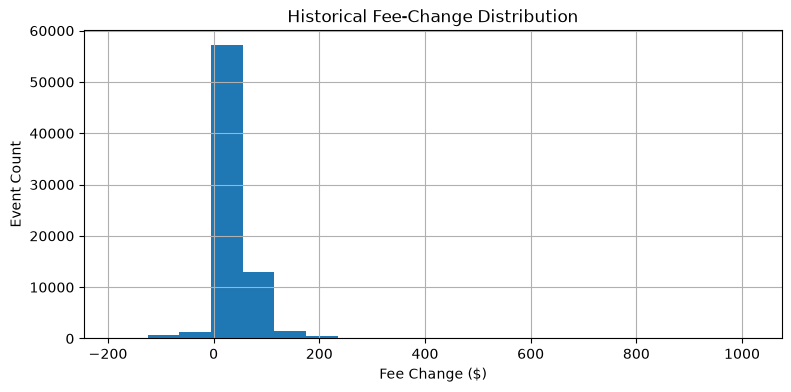

In [9]:
if len(event_df):
    coverage=[]
    for w in EVENT_WINDOWS:
        complete = (event_df[f"pre_{w}w_weeks"].ge(max(1, int(w*0.75))) &
                    event_df[f"post_{w}w_weeks"].ge(max(1, int(w*0.75))))
        coverage.append({"Window":f"{w}W","Events":len(event_df),"Adequate_Coverage":int(complete.sum()),"Pct":complete.mean()})
    coverage_df=pd.DataFrame(coverage)
    display(coverage_df)

    summary = pd.DataFrame({
        "Metric":["Unique events","Fee increases","Fee decreases","Locations","Price tiers","Median fee change $","Median fee change %"],
        "Value":[len(event_df),
                 int((event_df["fee_change_amount"]>0).sum()),
                 int((event_df["fee_change_amount"]<0).sum()),
                 event_df["VRLOCATION"].nunique(), event_df["price_tier"].nunique(),
                 event_df["fee_change_amount"].median(), event_df["fee_change_pct"].median()]
    })
    display(summary)

    plt.figure(figsize=(9,4))
    event_df["fee_change_amount"].dropna().hist(bins=min(20,max(5,event_df["fee_change_amount"].nunique())))
    plt.title("Historical Fee-Change Distribution")
    plt.xlabel("Fee Change ($)")
    plt.ylabel("Event Count")
    plt.show()
else:
    print("No usable fee-change events found.")

## 9. Test the report's -0.50 elasticity benchmark
The report implies approximately:

\[

rac{\%\Delta Volume}{\%\Delta Fee} pprox -0.50
\]

For each sufficiently covered event, this section calculates observed control-adjusted elasticity:

\[
Elasticity_i = 
rac{Adjusted\ Volume\ Change\%}{Fee\ Change\%}
\]

Because individual-event elasticity is noisy when fee changes are very small, we also estimate a regression slope through historical events. The output compares the empirical result against **-0.50**.

Usable observations for elasticity regression: 62482
Empirical slope: 0.015
Report benchmark: -0.500
Difference: +0.515


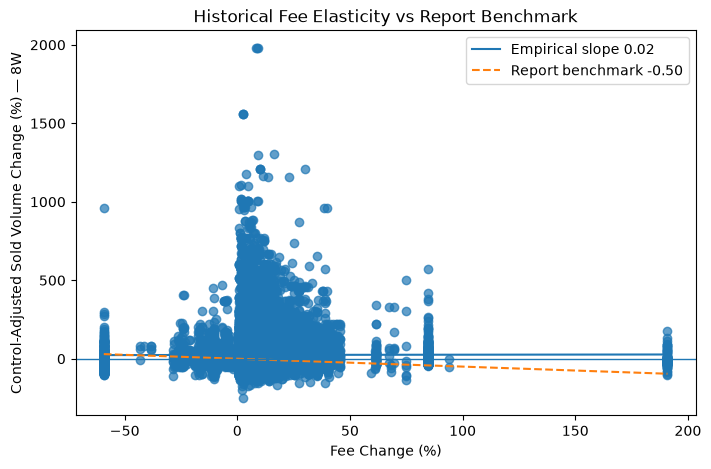

In [10]:
W = PRIMARY_WINDOW
analysis = event_df.copy() if len(event_df) else pd.DataFrame()

if len(analysis):
    analysis["observed_elasticity"] = np.where(
        analysis["fee_change_pct"].abs().gt(0.005),
        analysis[f"adj_volume_change_pct_{W}w"] / analysis["fee_change_pct"],
        np.nan
    )
    valid = analysis[["fee_change_pct",f"adj_volume_change_pct_{W}w"]].dropna()

    print("Usable observations for elasticity regression:", len(valid))
    if len(valid) >= 5 and valid["fee_change_pct"].nunique() >= 2:
        x = valid["fee_change_pct"].values
        y = valid[f"adj_volume_change_pct_{W}w"].values
        # slope with intercept for descriptive benchmark comparison
        slope, intercept = np.polyfit(x, y, 1)
        print(f"Empirical slope: {slope:.3f}")
        print(f"Report benchmark: {REPORT_ELASTICITY:.3f}")
        print(f"Difference: {slope-REPORT_ELASTICITY:+.3f}")

        plt.figure(figsize=(8,5))
        plt.scatter(x*100, y*100, alpha=.7)
        xx=np.linspace(x.min(),x.max(),100)
        plt.plot(xx*100,(intercept+slope*xx)*100,label=f"Empirical slope {slope:.2f}")
        plt.plot(xx*100,(REPORT_ELASTICITY*xx)*100,linestyle="--",label="Report benchmark -0.50")
        plt.axhline(0, linewidth=1)
        plt.xlabel("Fee Change (%)")
        plt.ylabel(f"Control-Adjusted Sold Volume Change (%) — {W}W")
        plt.title("Historical Fee Elasticity vs Report Benchmark")
        plt.legend()
        plt.show()
    else:
        print("Insufficient historical events to estimate an empirical elasticity slope reliably.")
else:
    print("No event-study dataset available.")

## 10. Build model-ready event dataset
The primary models use the **8-week** (configurable) control-adjusted outcomes.

### Features
- Fee change $ and %
- Previous fee
- Price tier
- Location and lane
- Pre-period sold volume
- Pre-period conversion
- Pre-period RPU
- Pre-period registered volume
- Vehicle-mix baselines
- Event month/year

### Targets
- `adj_volume_change_pct_8w`
- `adj_conversion_change_pp_8w`
- `adj_rpu_change_pct_8w`

This event-level structure makes the unit of analysis the actual pricing intervention—not an individual VIN.

In [11]:
if len(event_df):
    W=PRIMARY_WINDOW
    model_df = event_df.copy()
    model_df["previous_fee"] = pd.to_numeric(model_df["previous_fee"], errors="coerce")
    model_df["fee_change_amount"] = pd.to_numeric(model_df["fee_change_amount"], errors="coerce")
    model_df["fee_change_pct"] = pd.to_numeric(model_df["fee_change_pct"], errors="coerce")

    # Require reasonable temporal coverage
    model_df = model_df[
        model_df[f"pre_{W}w_weeks"].ge(max(1,int(W*.75))) &
        model_df[f"post_{W}w_weeks"].ge(max(1,int(W*.75)))
    ].copy()

    model_df["baseline_sold_pw"] = model_df[f"pre_{W}w_sold_pw"]
    model_df["baseline_registered_pw"] = model_df[f"pre_{W}w_registered_pw"]
    model_df["baseline_conversion"] = model_df[f"pre_{W}w_conversion"]
    model_df["baseline_rpu"] = model_df[f"pre_{W}w_rpu"]
    model_df["baseline_avg_sale_price"] = model_df[f"pre_{W}w_avg_sale_price"]
    model_df["baseline_avg_mileage"] = model_df[f"pre_{W}w_avg_mileage"]
    model_df["baseline_avg_vehicle_age"] = model_df[f"pre_{W}w_avg_vehicle_age"]

    targets = {
        "Volume": f"adj_volume_change_pct_{W}w",
        "Conversion": f"adj_conversion_change_pp_{W}w",
        "RPU": f"adj_rpu_change_pct_{W}w"
    }
    features = [
        "fee_change_amount","fee_change_pct","previous_fee","price_tier_low",
        "baseline_sold_pw","baseline_registered_pw","baseline_conversion","baseline_rpu",
        "baseline_avg_sale_price","baseline_avg_mileage","baseline_avg_vehicle_age",
        "event_month","event_year","VRLOCATION","LANE","price_tier"
    ]
    features=[c for c in features if c in model_df.columns]
    print("Model-ready events:", len(model_df))
    display(model_df[["event_id"]+features+list(targets.values())].head())
else:
    model_df=pd.DataFrame(); features=[]; targets={}

Model-ready events: 25381


,event_id,fee_change_amount,fee_change_pct,previous_fee,price_tier_low,baseline_sold_pw,baseline_registered_pw,baseline_conversion,baseline_rpu,baseline_avg_sale_price,baseline_avg_mileage,baseline_avg_vehicle_age,event_month,event_year,VRLOCATION,LANE,price_tier,adj_volume_change_pct_8w,adj_conversion_change_pp_8w,adj_rpu_change_pct_8w
1,2,10.0,0.032258,310.0,12000.0,2.750000,7.500000,0.366667,330.000000,12304.761905,124573.138381,9.606090,7,2023,MINNESOTA,2,12000-13000,-0.160474,10.400704,0.025708
3,4,10.0,0.040000,250.0,6000.0,5.875000,9.875000,0.594937,270.638298,6412.857143,142809.380952,10.587148,7,2023,MINNESOTA,2,6000-7000,0.249649,2.358881,-0.034036
4,5,10.0,0.040000,250.0,6000.0,7.375000,11.875000,0.621053,280.677966,6367.767857,139466.108823,10.202809,12,2023,MINNESOTA,2,6000-7000,-0.257999,-7.006767,-0.056529
5,6,20.0,0.044444,450.0,9000.0,1.428571,2.428571,0.588235,388.500000,9627.777778,106875.500000,9.047619,7,2023,COLUMBUS,5,9000-10000,0.719802,7.013017,0.116733
6,7,20.0,0.057971,345.0,5000.0,4.125000,7.000000,0.589286,345.000000,5349.479167,120448.206101,10.147917,7,2023,LASVEGAS,3,5000-6000,-0.213795,-2.851744,-0.026764


## 11. Train interpretable + nonlinear models with chronological backtesting
Two model families are used for each target:

1. **Ridge regression** — stable and interpretable baseline.
2. **Random Forest** — captures nonlinear thresholds and interactions.

The final scenario estimate blends the two when both are available. Evaluation uses a **chronological split**, not a random split, because we care about performance on future fee changes.

Metrics:
- MAE
- R²
- Direction accuracy (whether the model gets increase/decrease direction correct)

If there are fewer than `MIN_EVENTS_TO_TRAIN`, training is intentionally skipped.

In [13]:
def make_ohe():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )


def build_pipeline(model, X):

    # ---------------------------------------------------------
    # FIX:
    # Anything that is truly numeric goes into numeric pipeline.
    # Everything else (Location, State, Lane, etc.) is categorical.
    # ---------------------------------------------------------

    numeric = [
        c for c in X.columns
        if pd.api.types.is_numeric_dtype(X[c])
    ]

    categorical = [
        c for c in X.columns
        if c not in numeric
    ]

    # Helpful validation
    print("\n-----------------------------------")
    print("MODEL INPUT CHECK")
    print("-----------------------------------")
    print("Numeric columns:")
    print(numeric)

    print("\nCategorical columns:")
    print(categorical)

    # ---------------------------------------------------------
    # Numeric preprocessing
    # ---------------------------------------------------------

    num_pipe = Pipeline([
        (
            "impute",
            SimpleImputer(strategy="median")
        ),
        (
            "scale",
            StandardScaler()
        )
    ])

    # ---------------------------------------------------------
    # Categorical preprocessing
    # ---------------------------------------------------------

    cat_pipe = Pipeline([
        (
            "impute",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "ohe",
            make_ohe()
        )
    ])

    # ---------------------------------------------------------
    # Combine preprocessing
    # ---------------------------------------------------------

    prep = ColumnTransformer(
        transformers=[
            ("num", num_pipe, numeric),
            ("cat", cat_pipe, categorical)
        ],
        remainder="drop"
    )

    # ---------------------------------------------------------
    # Final ML pipeline
    # ---------------------------------------------------------

    return Pipeline([
        ("prep", prep),
        ("model", model)
    ])

models={}
metrics=[]

if len(model_df) < MIN_EVENTS_TO_TRAIN:
    print(f"TRAINING SKIPPED: only {len(model_df)} adequately covered events; minimum configured = {MIN_EVENTS_TO_TRAIN}.")
    print("Use the full historical VIN/fee timeline. The notebook will automatically train once the threshold is met.")
else:
    temp=model_df.sort_values("event_date").copy()
    split=max(1,int(len(temp)*0.80))
    train=temp.iloc[:split].copy(); test=temp.iloc[split:].copy()
    print(f"Chronological split: train={len(train)}, test={len(test)}")

    for label,target in targets.items():
        tr=train.dropna(subset=[target]).copy(); te=test.dropna(subset=[target]).copy()
        if len(tr)<20 or len(te)<3:
            print(f"Skipping {label}: not enough non-null target rows.")
            continue
        Xtr,ytr=tr[features],tr[target]
        Xte,yte=te[features],te[target]

        ridge=build_pipeline(Ridge(alpha=10.0), Xtr)
        rf=build_pipeline(RandomForestRegressor(
            n_estimators=350, min_samples_leaf=max(2,int(len(tr)*0.02)),
            max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1
        ), Xtr)
        ridge.fit(Xtr,ytr); rf.fit(Xtr,ytr)
        p1=ridge.predict(Xte); p2=rf.predict(Xte); pred=(p1+p2)/2

        mae=mean_absolute_error(yte,pred)
        r2=r2_score(yte,pred) if len(yte)>1 else np.nan
        direction=np.mean(np.sign(pred)==np.sign(yte))
        metrics.append({"Target":label,"Train_Events":len(tr),"Test_Events":len(te),"MAE":mae,"R2":r2,"Direction_Accuracy":direction})

        # Refit on all available rows after backtest
        allv=temp.dropna(subset=[target]).copy()
        ridge_full=build_pipeline(Ridge(alpha=10.0), allv[features]); ridge_full.fit(allv[features],allv[target])
        rf_full=build_pipeline(RandomForestRegressor(
            n_estimators=500,min_samples_leaf=max(2,int(len(allv)*0.02)),max_features="sqrt",
            random_state=RANDOM_STATE,n_jobs=-1
        ), allv[features]); rf_full.fit(allv[features],allv[target])
        models[label]={"ridge":ridge_full,"rf":rf_full,"target":target}

    metrics_df=pd.DataFrame(metrics)
    display(metrics_df)

Chronological split: train=20304, test=5077

-----------------------------------
MODEL INPUT CHECK
-----------------------------------
Numeric columns:
['fee_change_amount', 'fee_change_pct', 'previous_fee', 'price_tier_low', 'baseline_sold_pw', 'baseline_registered_pw', 'baseline_conversion', 'baseline_rpu', 'baseline_avg_sale_price', 'baseline_avg_mileage', 'baseline_avg_vehicle_age', 'event_month', 'event_year']

Categorical columns:
['VRLOCATION', 'LANE', 'price_tier']

-----------------------------------
MODEL INPUT CHECK
-----------------------------------
Numeric columns:
['fee_change_amount', 'fee_change_pct', 'previous_fee', 'price_tier_low', 'baseline_sold_pw', 'baseline_registered_pw', 'baseline_conversion', 'baseline_rpu', 'baseline_avg_sale_price', 'baseline_avg_mileage', 'baseline_avg_vehicle_age', 'event_month', 'event_year']

Categorical columns:
['VRLOCATION', 'LANE', 'price_tier']

-----------------------------------
MODEL INPUT CHECK
---------------------------------

,Target,Train_Events,Test_Events,MAE,R2,Direction_Accuracy
0,Volume,20275,5072,0.327467,0.177916,0.581427
1,Conversion,20304,5077,10.147562,0.189103,0.668111
2,RPU,20150,5068,0.061471,0.242978,0.682123


## 12. Scenario simulator: +$10 / +$15 / +$20 / +$25 / +$30
For each historical baseline segment, the simulator changes only the hypothetical fee increment while keeping baseline business conditions fixed.

For each scenario it predicts:
- Sold-volume attrition %
- Conversion change in percentage points
- RPU change %
- Projected sold units
- Projected conversion
- Projected RPU
- Projected buy-fee revenue change %

The table also shows the **existing report benchmark** so the new model can be directly compared with the report's -0.50 elasticity assumption.

In [14]:
def predict_blend(label, X):
    m=models[label]
    return (m["ridge"].predict(X)+m["rf"].predict(X))/2


def make_scenarios(baseline_row, increments=SCENARIOS):
    rows=[]
    for inc in increments:
        r=baseline_row.copy()
        prev=float(r["previous_fee"]) if pd.notna(r["previous_fee"]) and r["previous_fee"]>0 else float(r.get("baseline_rpu", np.nan))
        r["previous_fee"]=prev
        r["fee_change_amount"]=inc
        r["fee_change_pct"]=inc/prev if prev and pd.notna(prev) else np.nan
        rows.append(r)
    return pd.DataFrame(rows)

scenario_output=pd.DataFrame()

if not models:
    print("Scenario ML predictions are not generated because training did not pass the minimum-event threshold.")
    print("The report benchmark can still be calculated from any baseline fee:")
    demo_fee = float(model_df["previous_fee"].dropna().median()) if len(model_df) and model_df["previous_fee"].notna().any() else 500.0
    demo=[]
    for inc in SCENARIOS:
        pct=inc/demo_fee
        demo.append({"Fee_Increase_$":inc,"Baseline_Fee_$":demo_fee,"Fee_Change_%":pct,
                     "Report_Implied_Volume_Change_%":REPORT_ELASTICITY*pct})
    demo_df=pd.DataFrame(demo)
    display(demo_df.style.format({"Fee_Change_%":"{:.2%}","Report_Implied_Volume_Change_%":"{:.2%}"}))
else:
    # Use latest event baseline for each Location/Lane/Tier as a scenario anchor
    base=(model_df.sort_values("event_date")
          .dropna(subset=["previous_fee"])
          .groupby(["VRLOCATION","LANE","price_tier"],as_index=False)
          .tail(1).copy())
    all_rows=[]
    for _,b in base.iterrows():
        s=make_scenarios(b,SCENARIOS)
        X=s[features]
        s["pred_volume_change_pct"]=predict_blend("Volume",X) if "Volume" in models else np.nan
        s["pred_conversion_change_pp"]=predict_blend("Conversion",X) if "Conversion" in models else np.nan
        s["pred_rpu_change_pct"]=predict_blend("RPU",X) if "RPU" in models else np.nan
        s["report_volume_change_pct"]=REPORT_ELASTICITY*s["fee_change_pct"]
        s["projected_sold_pw"]=s["baseline_sold_pw"]*(1+s["pred_volume_change_pct"])
        s["projected_conversion"]=(s["baseline_conversion"]+s["pred_conversion_change_pp"]/100).clip(0,1)
        s["projected_rpu"]=s["baseline_rpu"]*(1+s["pred_rpu_change_pct"])
        s["baseline_revenue_pw"]=s["baseline_sold_pw"]*s["baseline_rpu"]
        s["projected_revenue_pw"]=s["projected_sold_pw"]*s["projected_rpu"]
        s["projected_revenue_change_pct"]=(s["projected_revenue_pw"]/s["baseline_revenue_pw"]-1).replace([np.inf,-np.inf],np.nan)
        all_rows.append(s)
    scenario_output=pd.concat(all_rows,ignore_index=True)
    outcols=["VRLOCATION","LANE","price_tier","previous_fee","fee_change_amount","fee_change_pct",
             "report_volume_change_pct","pred_volume_change_pct","pred_conversion_change_pp","pred_rpu_change_pct",
             "baseline_sold_pw","projected_sold_pw","baseline_conversion","projected_conversion",
             "baseline_rpu","projected_rpu","projected_revenue_change_pct"]
    display(scenario_output[outcols].head(25))

,VRLOCATION,LANE,price_tier,previous_fee,fee_change_amount,fee_change_pct,report_volume_change_pct,pred_volume_change_pct,pred_conversion_change_pp,pred_rpu_change_pct,baseline_sold_pw,projected_sold_pw,baseline_conversion,projected_conversion,baseline_rpu,projected_rpu,projected_revenue_change_pct
0,COLUMBUS,7,35000-36000,590.0,10,0.016949,-0.008475,0.090446,-5.026009,-0.004033,1.714286,1.869335,0.750000,0.699740,590.000000,587.620738,0.086048
1,COLUMBUS,7,35000-36000,590.0,15,0.025424,-0.012712,0.089477,-5.075502,-0.002205,1.714286,1.867675,0.750000,0.699245,590.000000,588.699119,0.087075
2,COLUMBUS,7,35000-36000,590.0,20,0.033898,-0.016949,0.087605,-5.130246,-0.000353,1.714286,1.864465,0.750000,0.698698,590.000000,589.791535,0.087221
3,COLUMBUS,7,35000-36000,590.0,25,0.042373,-0.021186,0.086691,-5.120942,0.003075,1.714286,1.862900,0.750000,0.698791,590.000000,591.814187,0.090033
4,COLUMBUS,7,35000-36000,590.0,30,0.050847,-0.025424,0.086202,-5.151493,0.005129,1.714286,1.862060,0.750000,0.698485,590.000000,593.025859,0.091773
5,SOUTHWISCONSIN,B,13000-14000,435.0,10,0.022989,-0.011494,0.134551,-0.356762,-0.023619,1.285714,1.458708,0.642857,0.639290,435.000000,424.725685,0.107754
6,SOUTHWISCONSIN,B,13000-14000,435.0,15,0.034483,-0.017241,0.133732,-0.408096,-0.021806,1.285714,1.457655,0.642857,0.638776,435.000000,425.514272,0.109009
7,SOUTHWISCONSIN,B,13000-14000,435.0,20,0.045977,-0.022989,0.132947,-0.413940,-0.019584,1.285714,1.456646,0.642857,0.638718,435.000000,426.481111,0.110760
8,SOUTHWISCONSIN,B,13000-14000,435.0,25,0.057471,-0.028736,0.132221,-0.417612,-0.016149,1.285714,1.455713,0.642857,0.638681,435.000000,427.975040,0.113937
9,SOUTHWISCONSIN,B,13000-14000,435.0,30,0.068966,-0.034483,0.132052,-0.444163,-0.014176,1.285714,1.455495,0.642857,0.638416,435.000000,428.833647,0.116004


## 13. Portfolio-level scenario summary
This is the executive view. Segment predictions are weighted by baseline sold volume so a tiny lane/tier does not receive the same influence as a large one.

The result directly answers the planning question for +$10 through +$30 while preserving the detailed segment output for drill-down.

,Fee_Increase_$,Weighted_Fee_Change_%,Report_Implied_Volume_Change_%,Model_Volume_Change_%,Model_Conversion_Change_pp,Model_RPU_Change_%,Portfolio_Revenue_Change_%
0,10,3.81%,-1.90%,6.43%,-0.95,3.22%,10.42%
1,15,5.71%,-2.86%,6.37%,-1.00,3.49%,10.65%
2,20,7.62%,-3.81%,6.32%,-1.03,3.72%,10.83%
3,25,9.52%,-4.76%,6.27%,-1.05,4.08%,11.16%
4,30,11.43%,-5.71%,6.27%,-1.07,4.32%,11.39%


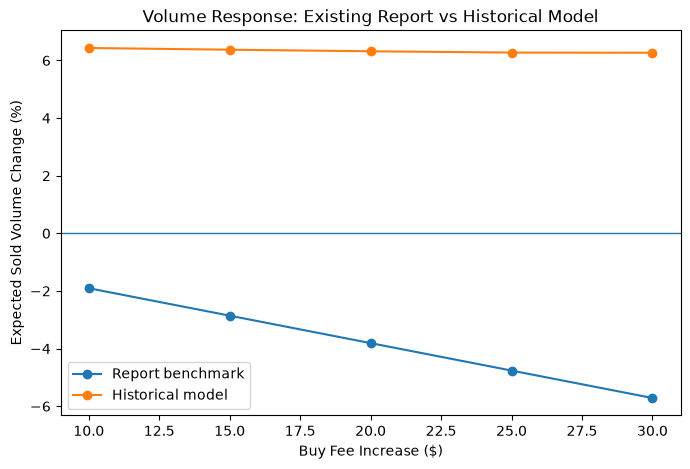

In [15]:
portfolio_summary=pd.DataFrame()
if len(scenario_output):
    rows=[]
    for inc,g in scenario_output.groupby("fee_change_amount"):
        w=g["baseline_sold_pw"].fillna(0).clip(lower=0)
        def wavg(col):
            x=g[col]
            m=x.notna() & w.gt(0)
            return np.average(x[m],weights=w[m]) if m.any() else np.nan
        base_rev=g["baseline_revenue_pw"].sum()
        proj_rev=g["projected_revenue_pw"].sum()
        rows.append({
            "Fee_Increase_$":inc,
            "Weighted_Fee_Change_%":wavg("fee_change_pct"),
            "Report_Implied_Volume_Change_%":wavg("report_volume_change_pct"),
            "Model_Volume_Change_%":wavg("pred_volume_change_pct"),
            "Model_Conversion_Change_pp":wavg("pred_conversion_change_pp"),
            "Model_RPU_Change_%":wavg("pred_rpu_change_pct"),
            "Portfolio_Revenue_Change_%":proj_rev/base_rev-1 if base_rev>0 else np.nan
        })
    portfolio_summary=pd.DataFrame(rows).sort_values("Fee_Increase_$")
    display(portfolio_summary.style.format({
        "Weighted_Fee_Change_%":"{:.2%}",
        "Report_Implied_Volume_Change_%":"{:.2%}",
        "Model_Volume_Change_%":"{:.2%}",
        "Model_Conversion_Change_pp":"{:.2f}",
        "Model_RPU_Change_%":"{:.2%}",
        "Portfolio_Revenue_Change_%":"{:.2%}"
    }))

    plt.figure(figsize=(8,5))
    plt.plot(portfolio_summary["Fee_Increase_$"],portfolio_summary["Report_Implied_Volume_Change_%"]*100,marker="o",label="Report benchmark")
    plt.plot(portfolio_summary["Fee_Increase_$"],portfolio_summary["Model_Volume_Change_%"]*100,marker="o",label="Historical model")
    plt.axhline(0,linewidth=1)
    plt.xlabel("Buy Fee Increase ($)")
    plt.ylabel("Expected Sold Volume Change (%)")
    plt.title("Volume Response: Existing Report vs Historical Model")
    plt.legend(); plt.show()
else:
    print("Portfolio scenario summary will populate after successful model training.")

## 14. Sensitivity table independent of ML
Even before the ML model is production-ready, this table is useful for governance. It shows what happens under alternative elasticity assumptions rather than committing to -0.50.

For example, compare -0.25, -0.50, -0.75 and -1.00. This helps show how much of a recommendation depends on the elasticity assumption itself.

In [16]:
base_fee = float(model_df["previous_fee"].dropna().median()) if len(model_df) and model_df["previous_fee"].notna().any() else 500.0
elasticities=[-0.25,-0.50,-0.75,-1.00]
sens=[]
for inc in SCENARIOS:
    fee_pct=inc/base_fee
    for e in elasticities:
        sens.append({"Baseline_Fee_$":base_fee,"Fee_Increase_$":inc,"Fee_Change_%":fee_pct,"Elasticity":e,"Implied_Volume_Change_%":e*fee_pct})
sensitivity=pd.DataFrame(sens)
display(sensitivity.pivot(index="Fee_Increase_$",columns="Elasticity",values="Implied_Volume_Change_%").style.format("{:.2%}"))

Elasticity,-1.000000,-0.750000,-0.500000,-0.250000
Fee_Increase_$,,,,
10,-2.60%,-1.95%,-1.30%,-0.65%
15,-3.90%,-2.92%,-1.95%,-0.97%
20,-5.19%,-3.90%,-2.60%,-1.30%
25,-6.49%,-4.87%,-3.25%,-1.62%
30,-7.79%,-5.84%,-3.90%,-1.95%


## 15. Export model diagnostics and scenario outputs
The exported files are intended for review in Excel/Tableau and for traceability during model validation.

In [17]:
exports={
    "fee_change_events.csv": events,
    "weekly_model_panel.csv": panel,
    "event_study_diagnostics.csv": event_df,
    "model_ready_events.csv": model_df,
    "scenario_detail.csv": scenario_output,
    "portfolio_scenario_summary.csv": portfolio_summary,
    "elasticity_sensitivity.csv": sensitivity,
}
for name,df in exports.items():
    if isinstance(df,pd.DataFrame):
        df.to_csv(OUTPUT_DIR/name,index=False)
        print("Saved",OUTPUT_DIR/name)

Saved buy_fee_model_outputs\fee_change_events.csv
Saved buy_fee_model_outputs\weekly_model_panel.csv
Saved buy_fee_model_outputs\event_study_diagnostics.csv
Saved buy_fee_model_outputs\model_ready_events.csv
Saved buy_fee_model_outputs\scenario_detail.csv
Saved buy_fee_model_outputs\portfolio_scenario_summary.csv
Saved buy_fee_model_outputs\elasticity_sensitivity.csv


# How to interpret the results

## A. Validate the old report first
The first question is **not** “Which ML algorithm has the best R²?” It is:

> **Does AAA's own historical data support the report assumption of -0.50 volume elasticity?**

If empirical elasticity is materially different, the recommendation report's revenue opportunity should be recalculated.

## B. Look for heterogeneity
A single network coefficient may hide important differences. Examine response by:
- Location
- Lane
- Vehicle price tier
- Current fee level
- Fee-to-sale-price ratio
- Size of fee increase
- Time since fee change

A +$25 increase on a low-value vehicle can represent a much larger relative change than +$25 on a high-value vehicle.

## C. Conversion is a leading behavioral indicator
If sold volume falls but registered units are stable, and conversion declines after fee increases, that is more consistent with buyer-side friction than a supply reduction.

## D. RPU pass-through matters
Do not assume a +$25 published fee increase creates +$25 realized RPU. Compare actual RPU response to the schedule change. Partial pass-through materially affects revenue forecasts.

## E. Revenue is the final business trade-off
For every scenario:

\[
Projected\ Revenue = Projected\ Sold\ Units 	imes Projected\ RPU
\]

The practical goal is to understand the **revenue/volume frontier**, not merely to maximize fee or minimize attrition.

# Production-readiness checklist
Before using the model for pricing decisions, verify:

- Sufficient independent fee-change events, preferably 75+ and ideally hundreds.
- Multiple locations and price tiers represented.
- Both smaller and larger fee increases represented.
- Adequate 8–12 week pre/post history.
- Overlapping fee changes identified and handled.
- No leakage from post-change information into predictors.
- Chronological backtest performance is stable.
- Direction accuracy is meaningfully above chance.
- Estimated effects are economically plausible and stable by time period.
- Predictions include uncertainty ranges before being used for policy/pricing decisions.

## Recommended next enhancement
Once the full historical data is loaded, add **bootstrap confidence intervals** and a fixed-effects/event-study specification (Location × Tier and calendar-week effects). Those will give the strongest statistical validation of whether the observed fee-response relationship is stable enough to support the scenario simulator.